# 02.03. IPCA — Análise por Itens



## PARTE 0 — Hierarquia • Variação • Peso • Contribuição • Impacto • Difusão • Concentração

Este notebook aprofunda a decomposição da inflação iniciada nos
notebooks anteriores:

* 02.ipca $\to\qquad$ IPCA geral
* 02.01.grupos $\to\qquad$ grandes componentes
* 02.02.subgrupos $\to\qquad$ componentes intermediários
* 02.03.itens $\to\qquad$ categorias mais específicas


O notebook assume que:

- os pipelines já foram executados;
- `bcb.ipca_itens` está atualizada;
- `bcb.ipca_subgrupos` está atualizada;
- `bcb.ipca_grupos` está atualizada;
- a auditoria dos dados foi concluída.

Este notebook NÃO executa pipelines e NÃO altera o banco de dados.




### Objetivos

1. Entender a posição dos itens na hierarquia do IPCA.
2. Relacionar cada item ao seu subgrupo e grupo.
3. Examinar variação e peso dos itens.
4. Calcular contribuição e impacto.
5. Identificar as principais pressões inflacionárias.
6. Medir a difusão da inflação entre itens.
7. Medir a concentração das pressões.
8. Verificar a consistência entre itens e subgrupos.
9. Preparar representações para futura engenharia de features.


---

### 1. Hierarquia do IPCA

Neste projeto utilizamos:

```text
grupo      -> código de 1 dígito
subgrupo   -> código de 2 dígitos
item       -> código de 4 dígitos
subitem    -> código de 7 dígitos
```

Um item pertence simultaneamente a:

```text
grupo
  |
  +-- subgrupo
         |
         +-- item
                |
                +-- subitem
```

Como os códigos são hierárquicos:

- primeiro dígito do item -> grupo;
- primeiros dois dígitos -> subgrupo;
- quatro dígitos -> item.

### 2. O que o nível de item acrescenta?

* Em `02.01.grupos`, perguntamos:  
    >   Quais grandes blocos explicaram a inflação?

* Em `02.02.subgrupos`, aprofundamos:
    > Quais componentes internos explicaram cada grupo?

* Agora queremos chegar a:
    > Quais categorias específicas foram mais relevantes para o movimento da inflação?

À medida que a granularidade aumenta, torna-se menos eficiente analisar
todas as séries individualmente.

O foco passa progressivamente para:

- rankings;
- impacto;
- direção;
- difusão;
- concentração;
- persistência;
- composição hierárquica.

### 3. Variação, peso, contribuição e impacto

Seja $\pi_{i,t}$ a variação mensal do item $i$ no período $t$.

Seja $w_{i,t}$ seu peso publicado.

Utilizamos a contribuição aproximada:

$$
C_{i,t}=\pi_{i,t}\frac{w_{i,t}}{100}
$$

A contribuição preserva o sinal.

Para medir a intensidade da pressão, independentemente da direção,
definimos:

$$
I_{i,t}=\left|C_{i,t}\right|
$$

Portanto:

* indice $\to\qquad$ intensidade da variação de preços
* peso $\to\qquad$ importância relativa
* contribuicao $\to\qquad$ efeito com direção
* impacto $\to\qquad$ magnitude da pressão


### 4. Configuração do ambiente

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: /home/moacir/projects/ml/analytics/inflation


### 5. Importações

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.database.connection import engine

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:.4f}".format)

### 6. Carregar itens do PostgreSQL

In [3]:
itens = pd.read_sql(
    """
    SELECT
        date,
        categoria,
        categoria_nome,
        indice,
        peso
    FROM bcb.ipca_itens
    ORDER BY date, categoria;
    """,
    engine,
)

#### 6.1 Preparar os dados

In [4]:
itens["date"] = pd.to_datetime(
    itens["date"]
)

itens["categoria"] = (
    itens["categoria"]
    .astype(str)
)

itens = (
    itens
    .sort_values(
        ["date", "categoria"]
    )
    .reset_index(drop=True)
)

#### 6.2 Identificar grupo e subgrupo

Como o código do item possui 4 dígitos:

```text
primeiro dígito     -> grupo
dois primeiros      -> subgrupo
quatro dígitos      -> item
```

In [5]:
itens["grupo_codigo"] = (
    itens["categoria"]
    .str[:1]
)

itens["subgrupo_codigo"] = (
    itens["categoria"]
    .str[:2]
)

#### 6.3 Calcular contribuição e impacto

In [6]:
itens["contribuicao"] = (
    itens["indice"]
    * itens["peso"]
    / 100
)

itens["impacto"] = (
    itens["contribuicao"]
    .abs()
)

#### 6.4 Direção da contribuição

In [7]:
itens["direcao"] = np.select(
    [
        itens["contribuicao"] > 0,
        itens["contribuicao"] < 0,
    ],
    [
        "positiva",
        "negativa",
    ],
    default="neutra",
)

itens.head(10)

,date,categoria,categoria_nome,indice,peso,grupo_codigo,subgrupo_codigo,contribuicao,impacto,direcao
0,2020-01-01,1101,"Cereais, leguminosas e oleaginosas",0.7500,0.6927,1,11,0.0052,0.0052,positiva
1,2020-01-01,1102,"Farinhas, féculas e massas",0.9000,0.4494,1,11,0.0040,0.0040,positiva
2,2020-01-01,1103,"Tubérculos, raízes e legumes",7.8100,0.5280,1,11,0.0412,0.0412,positiva
3,2020-01-01,1104,Açúcares e derivados,0.7400,0.6189,1,11,0.0046,0.0046,positiva
4,2020-01-01,1105,Hortaliças e verduras,2.5200,0.1810,1,11,0.0046,0.0046,positiva
5,2020-01-01,1106,Frutas,1.8700,0.8482,1,11,0.0159,0.0159,positiva
6,2020-01-01,1107,Carnes,-4.0300,2.6658,1,11,-0.1074,0.1074,negativa
7,2020-01-01,1108,Pescados,3.3900,0.2177,1,11,0.0074,0.0074,positiva
8,2020-01-01,1109,Carnes e peixes industrializados,1.6400,0.6243,1,11,0.0102,0.0102,positiva
9,2020-01-01,1110,Aves e ovos,2.0600,1.1254,1,11,0.0232,0.0232,positiva


### 7. Carregar referências hierárquicas

In [8]:
grupos_ref = pd.read_sql(
    """
    SELECT DISTINCT
        categoria,
        categoria_nome
    FROM bcb.ipca_grupos
    ORDER BY categoria;
    """,
    engine,
)

subgrupos_ref = pd.read_sql(
    """
    SELECT DISTINCT
        categoria,
        categoria_nome
    FROM bcb.ipca_subgrupos
    ORDER BY categoria;
    """,
    engine,
)

#### 7.1 Preparar referências

In [9]:
grupos_ref["categoria"] = (
    grupos_ref["categoria"]
    .astype(str)
)

subgrupos_ref["categoria"] = (
    subgrupos_ref["categoria"]
    .astype(str)
)

grupos_ref = grupos_ref.rename(
    columns={
        "categoria": "grupo_codigo",
        "categoria_nome": "grupo_nome",
    }
)

subgrupos_ref = subgrupos_ref.rename(
    columns={
        "categoria": "subgrupo_codigo",
        "categoria_nome": "subgrupo_nome",
    }
)

#### 7.2 Associar a hierarquia aos itens

In [10]:
itens = (
    itens
    .merge(
        grupos_ref,
        on="grupo_codigo",
        how="left",
        validate="many_to_one",
    )
    .merge(
        subgrupos_ref,
        on="subgrupo_codigo",
        how="left",
        validate="many_to_one",
    )
)

itens[
    [
        "grupo_codigo",
        "grupo_nome",
        "subgrupo_codigo",
        "subgrupo_nome",
        "categoria",
        "categoria_nome",
    ]
].drop_duplicates().head(30)

,grupo_codigo,grupo_nome,subgrupo_codigo,subgrupo_nome,categoria,categoria_nome
0,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas"
1,1,Alimentação e bebidas,11,Alimentação no domicílio,1102,"Farinhas, féculas e massas"
2,1,Alimentação e bebidas,11,Alimentação no domicílio,1103,"Tubérculos, raízes e legumes"
3,1,Alimentação e bebidas,11,Alimentação no domicílio,1104,Açúcares e derivados
4,1,Alimentação e bebidas,11,Alimentação no domicílio,1105,Hortaliças e verduras
5,1,Alimentação e bebidas,11,Alimentação no domicílio,1106,Frutas
6,1,Alimentação e bebidas,11,Alimentação no domicílio,1107,Carnes
7,1,Alimentação e bebidas,11,Alimentação no domicílio,1108,Pescados
8,1,Alimentação e bebidas,11,Alimentação no domicílio,1109,Carnes e peixes industrializados
9,1,Alimentação e bebidas,11,Alimentação no domicílio,1110,Aves e ovos


### 8. Cobertura histórica

In [11]:
resumo = pd.DataFrame(
    [
        {
            "inicio": itens["date"].min(),
            "fim": itens["date"].max(),
            "observacoes": len(itens),
            "itens": itens["categoria"].nunique(),
            "subgrupos": itens["subgrupo_codigo"].nunique(),
            "grupos": itens["grupo_codigo"].nunique(),
        }
    ]
)

resumo

,inicio,fim,observacoes,itens,subgrupos,grupos
0,2020-01-01,2026-08-01,4080,51,19,9


### 9. Catálogo hierárquico

In [14]:
catalogo = (
    itens[
        [
            "grupo_codigo",
            "grupo_nome",
            "subgrupo_codigo",
            "subgrupo_nome",
            "categoria",
            "categoria_nome",
        ]
    ]
    .drop_duplicates()
    .sort_values(
        [
            "grupo_codigo",
            "subgrupo_codigo",
            "categoria",
        ]
    )
    .reset_index(drop=True)
)

catalogo.head(20)

,grupo_codigo,grupo_nome,subgrupo_codigo,subgrupo_nome,categoria,categoria_nome
0,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas"
1,1,Alimentação e bebidas,11,Alimentação no domicílio,1102,"Farinhas, féculas e massas"
2,1,Alimentação e bebidas,11,Alimentação no domicílio,1103,"Tubérculos, raízes e legumes"
3,1,Alimentação e bebidas,11,Alimentação no domicílio,1104,Açúcares e derivados
4,1,Alimentação e bebidas,11,Alimentação no domicílio,1105,Hortaliças e verduras
5,1,Alimentação e bebidas,11,Alimentação no domicílio,1106,Frutas
6,1,Alimentação e bebidas,11,Alimentação no domicílio,1107,Carnes
7,1,Alimentação e bebidas,11,Alimentação no domicílio,1108,Pescados
8,1,Alimentação e bebidas,11,Alimentação no domicílio,1109,Carnes e peixes industrializados
9,1,Alimentação e bebidas,11,Alimentação no domicílio,1110,Aves e ovos


### 10. Quantidade de itens por subgrupo

Isso nos ajuda a entender como a granularidade está distribuída
dentro da hierarquia.

In [15]:
quantidade_por_subgrupo = (
    catalogo
    .groupby(
        [
            "grupo_nome",
            "subgrupo_codigo",
            "subgrupo_nome",
        ]
    )
    .size()
    .rename("itens")
    .reset_index()
    .sort_values(
        "itens",
        ascending=False,
    )
)

quantidade_por_subgrupo

,grupo_nome,subgrupo_codigo,subgrupo_nome,itens
0,Alimentação e bebidas,11,Alimentação no domicílio,16
8,Educação,81,"Cursos, leitura e papelaria",4
2,Artigos de residência,31,Móveis e utensílios,3
15,Vestuário,41,Roupas,3
9,Habitação,21,Encargos e manutenção,3
14,Transportes,51,Transportes,3
12,Saúde e cuidados pessoais,62,Serviços de saúde,3
11,Saúde e cuidados pessoais,61,Produtos farmacêuticos e óticos,2
10,Habitação,22,Combustíveis e energia,2
3,Artigos de residência,32,Aparelhos eletroeletrônicos,2


---

## PARTE I — ÚLTIMO MÊS




### 11. Último mês disponível

In [16]:
ultimo_mes = itens["date"].max()

itens_ultimo = (
    itens[
        itens["date"] == ultimo_mes
    ]
    .copy()
)

print(
    "Último mês disponível:",
    ultimo_mes.strftime("%Y-%m"),
)

print(
    "Itens disponíveis:",
    len(itens_ultimo),
)

Último mês disponível: 2026-08
Itens disponíveis: 51


### 12. Itens com maior peso

Esta análise responde:

> Quais itens possuem maior importância relativa na estrutura atual?

In [18]:
itens_ultimo[
    [
        "grupo_nome",
        "subgrupo_nome",
        "categoria_nome",
        "peso",
    ]
].sort_values(
    "peso",
    ascending=False,
).head(20)

,grupo_nome,subgrupo_nome,categoria_nome,peso
4064,Transportes,Transportes,Veículo próprio,10.9406
4046,Habitação,Encargos e manutenção,Aluguel e taxas,7.7518
4072,Despesas pessoais,Serviços pessoais,Serviços pessoais,6.3498
4045,Alimentação e bebidas,Alimentação fora do domicílio,Alimentação fora do domicílio,6.0877
4065,Transportes,Transportes,Combustíveis (veículos),6.0833
4075,Educação,"Cursos, leitura e papelaria",Cursos regulares,4.6754
4079,Comunicação,Comunicação,Comunicação,4.5011
4050,Habitação,Combustíveis e energia,Energia elétrica residencial,4.2960
4070,Saúde e cuidados pessoais,Serviços de saúde,Plano de saúde,4.1405
4071,Saúde e cuidados pessoais,Cuidados pessoais,Higiene pessoal,4.1025


### 13. Itens com maiores variações positivas

Aqui olhamos apenas para $\pi_{i,t}$.

Portanto, ainda não estamos levando em consideração a importância
relativa do item.

In [20]:
itens_ultimo[
    [
        "grupo_nome",
        "subgrupo_nome",
        "categoria_nome",
        "indice",
        "peso",
        "contribuicao",
        "impacto",
    ]
].nlargest(
    15,
    "indice",
)

,grupo_nome,subgrupo_nome,categoria_nome,indice,peso,contribuicao,impacto
4074,Despesas pessoais,Recreação e fumo,Fumo,19.5900,0.5785,0.1133,0.1133
4055,Artigos de residência,Aparelhos eletroeletrônicos,"Tv, som e informática",1.6900,0.6063,0.0102,0.0102
4067,Saúde e cuidados pessoais,Produtos farmacêuticos e óticos,Produtos óticos,1.6400,0.2379,0.0039,0.0039
4039,Alimentação e bebidas,Alimentação no domicílio,Leites e derivados,1.0600,1.8920,0.0201,0.0201
4034,Alimentação e bebidas,Alimentação no domicílio,Frutas,0.8400,1.1372,0.0096,0.0096
4060,Vestuário,Calçados e acessórios,Calçados e acessórios,0.7500,1.2178,0.0091,0.0091
4048,Habitação,Encargos e manutenção,Artigos de limpeza,0.7400,0.7292,0.0054,0.0054
4054,Artigos de residência,Aparelhos eletroeletrônicos,Eletrodomésticos e equipamentos,0.6800,0.7821,0.0053,0.0053
4051,Artigos de residência,Móveis e utensílios,Mobiliário,0.6500,1.1758,0.0076,0.0076
4043,Alimentação e bebidas,Alimentação no domicílio,Enlatados e conservas,0.6300,0.1601,0.0010,0.0010


### 14. Itens com maiores variações negativas

In [21]:
itens_ultimo[
    [
        "grupo_nome",
        "subgrupo_nome",
        "categoria_nome",
        "indice",
        "peso",
        "contribuicao",
        "impacto",
    ]
].nsmallest(
    15,
    "indice",
)

,grupo_nome,subgrupo_nome,categoria_nome,indice,peso,contribuicao,impacto
4031,Alimentação e bebidas,Alimentação no domicílio,"Tubérculos, raízes e legumes",-12.3700,0.8393,-0.1038,0.1038
4050,Habitação,Combustíveis e energia,Energia elétrica residencial,-7.6300,4.2960,-0.3278,0.3278
4063,Transportes,Transportes,Transporte público,-3.6700,3.2457,-0.1191,0.1191
4033,Alimentação e bebidas,Alimentação no domicílio,Hortaliças e verduras,-1.6100,0.2613,-0.0042,0.0042
4038,Alimentação e bebidas,Alimentação no domicílio,Aves e ovos,-1.5500,1.2142,-0.0188,0.0188
4037,Alimentação e bebidas,Alimentação no domicílio,Carnes e peixes industrializados,-0.9600,0.5954,-0.0057,0.0057
4065,Transportes,Transportes,Combustíveis (veículos),-0.9100,6.0833,-0.0554,0.0554
4042,Alimentação e bebidas,Alimentação no domicílio,Bebidas e infusões,-0.5200,1.8662,-0.0097,0.0097
4053,Artigos de residência,Móveis e utensílios,"Cama, mesa e banho",-0.4200,0.1690,-0.0007,0.0007
4057,Vestuário,Roupas,Roupa masculina,-0.3600,1.1619,-0.0042,0.0042


### 15. Principais pressões do mês

Para identificar os componentes mais relevantes para o movimento do IPCA,
utilizamos:

$$
I_{i,t}=|C_{i,t}|
$$

Assim, uma contribuição negativa de grande magnitude pode aparecer
acima de uma pequena contribuição positiva.

In [23]:
ranking_impacto = (
    itens_ultimo[
        [
            "grupo_nome",
            "subgrupo_nome",
            "categoria_nome",
            "indice",
            "peso",
            "contribuicao",
            "impacto",
            "direcao",
        ]
    ]
    .sort_values(
        "impacto",
        ascending=False,
    )
    .reset_index(drop=True)
)

ranking_impacto.head(20)

,grupo_nome,subgrupo_nome,categoria_nome,indice,peso,contribuicao,impacto,direcao
0,Habitação,Combustíveis e energia,Energia elétrica residencial,-7.6300,4.2960,-0.3278,0.3278,negativa
1,Transportes,Transportes,Transporte público,-3.6700,3.2457,-0.1191,0.1191,negativa
2,Despesas pessoais,Recreação e fumo,Fumo,19.5900,0.5785,0.1133,0.1133,positiva
3,Alimentação e bebidas,Alimentação no domicílio,"Tubérculos, raízes e legumes",-12.3700,0.8393,-0.1038,0.1038,negativa
4,Transportes,Transportes,Combustíveis (veículos),-0.9100,6.0833,-0.0554,0.0554,negativa
5,Habitação,Encargos e manutenção,Aluguel e taxas,0.3700,7.7518,0.0287,0.0287,positiva
6,Educação,"Cursos, leitura e papelaria",Cursos regulares,0.5200,4.6754,0.0243,0.0243,positiva
7,Despesas pessoais,Serviços pessoais,Serviços pessoais,0.3700,6.3498,0.0235,0.0235,positiva
8,Alimentação e bebidas,Alimentação fora do domicílio,Alimentação fora do domicílio,0.3600,6.0877,0.0219,0.0219,positiva
9,Alimentação e bebidas,Alimentação no domicílio,Leites e derivados,1.0600,1.8920,0.0201,0.0201,positiva


### 16. Gráfico das principais pressões

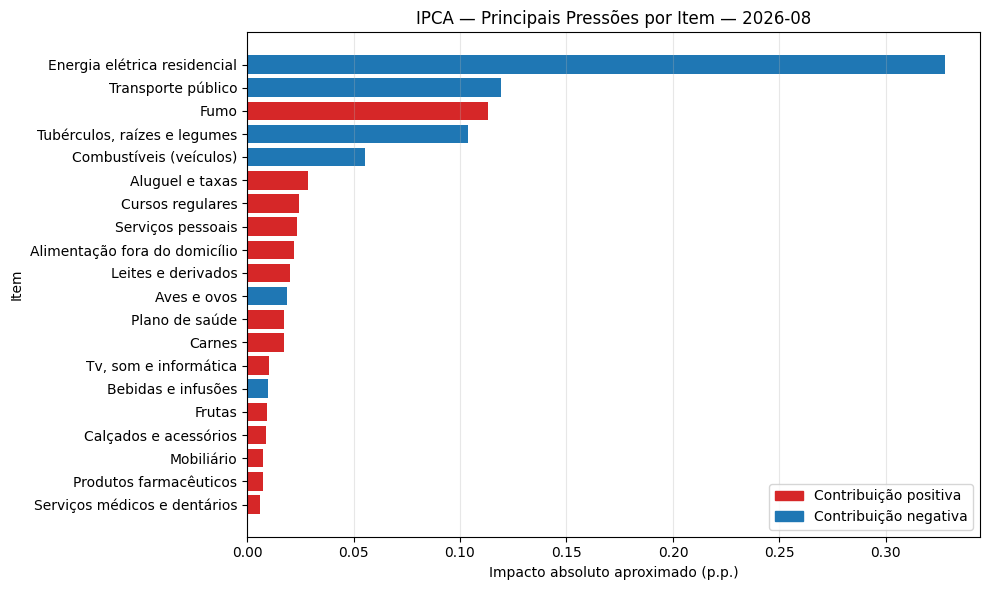

In [26]:
from matplotlib.patches import Patch

top_impacto = (
    ranking_impacto
    .head(20)
    .sort_values("impacto")
)

cores = np.where(
    top_impacto["contribuicao"] >= 0,
    "tab:red",
    "tab:blue",
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_impacto["categoria_nome"],
    top_impacto["impacto"],
    color=cores,
)

plt.title(
    f"IPCA — Principais Pressões por Item — {ultimo_mes:%Y-%m}"
)

plt.xlabel("Impacto absoluto aproximado (p.p.)")
plt.ylabel("Item")

plt.grid(
    True,
    axis="x",
    alpha=0.3,
)

legenda = [
    Patch(
        color="tab:red",
        label="Contribuição positiva",
    ),
    Patch(
        color="tab:blue",
        label="Contribuição negativa",
    ),
]

plt.legend(
    handles=legenda,
    loc="lower right",
)

plt.tight_layout()
plt.show()

### 17. Direção das principais pressões

O ranking anterior utiliza `impacto`, mas não mostra se cada componente
pressionou o índice para cima ou para baixo.

Para recuperar essa informação utilizamos `contribuicao`.

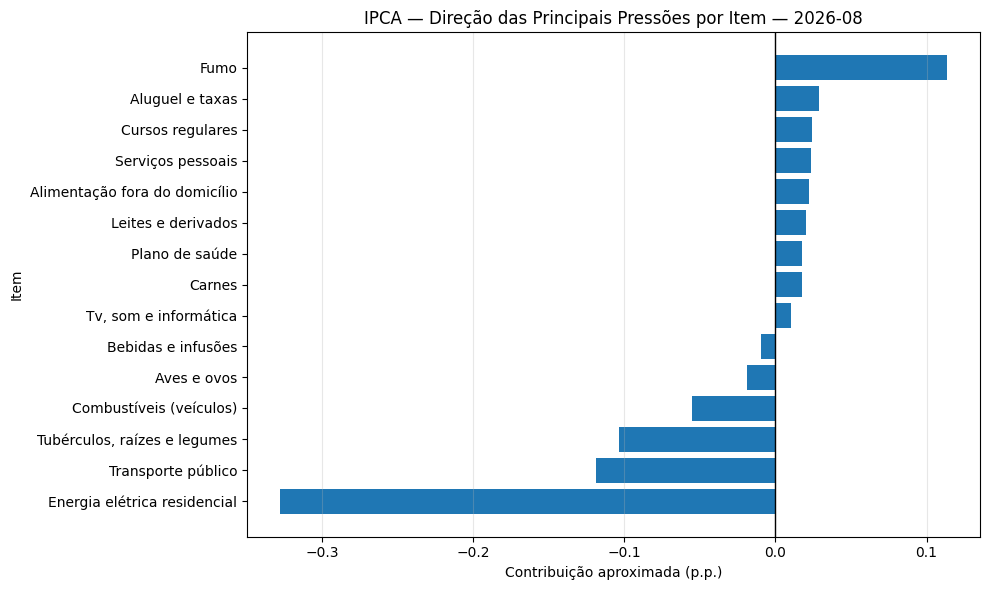

In [29]:
top_pressao_direcao = (
    itens_ultimo
    .sort_values(
        "impacto",
        ascending=False,
    )
    .head(15)
    .sort_values("contribuicao")
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_pressao_direcao["categoria_nome"],
    top_pressao_direcao["contribuicao"],
)

plt.axvline(
    0,
    color="black",
    linewidth=1,
)

plt.title(
    f"IPCA — Direção das Principais Pressões por Item — {ultimo_mes:%Y-%m}"
)

plt.xlabel("Contribuição aproximada (p.p.)")
plt.ylabel("Item")

plt.grid(
    True,
    axis="x",
    alpha=0.3,
)

plt.tight_layout()
plt.show()

### 18. Interpretação

As duas medidas são complementares.

* Impacto

$$
I_{i,t}=|C_{i,t}|
$$

responde:

> Qual item teve maior relevância para o movimento da inflação?

* Contribuição

$$
C_{i,t}=\pi_{i,t}\frac{w_{i,t}}{100}
$$

responde:

> Em qual direção esse item pressionou o índice?

---

## PARTE II — DISTRIBUIÇÃO DOS MOVIMENTOS



### 19. Distribuição da inflação dos itens

Diferentemente dos grupos, agora temos uma quantidade maior de
componentes.

Portanto, a distribuição passa a ser mais informativa.

O histograma abaixo responde:

> Como as variações de preços estão distribuídas entre os itens?

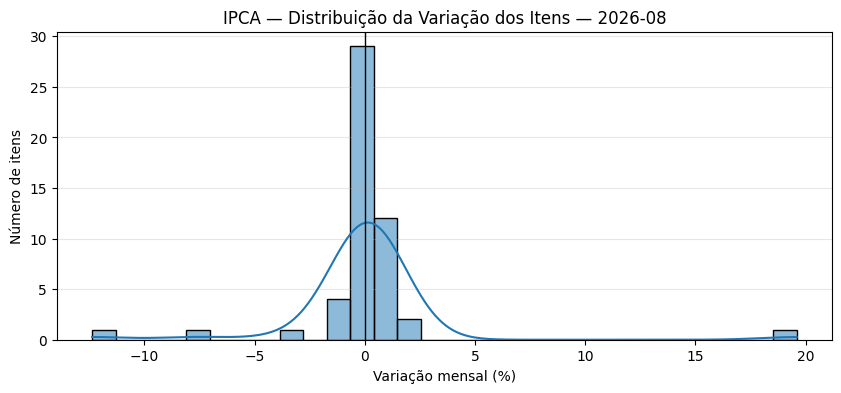

In [31]:
plt.figure(figsize=(10, 4))

sns.histplot(
    itens_ultimo["indice"],
    bins=30,
    kde=True,
)

plt.axvline(
    0,
    color="black",
    linewidth=1,
)

plt.title(
    f"IPCA — Distribuição da Variação dos Itens — {ultimo_mes:%Y-%m}"
)

plt.xlabel("Variação mensal (%)")
plt.ylabel("Número de itens")

plt.grid(
    True,
    axis="y",
    alpha=0.3,
)

plt.show()

### 20. Estatísticas da distribuição

In [32]:
itens_ultimo["indice"].describe()

count    51.0000
mean      0.0392
std       3.5433
min     -12.3700
25%      -0.1600
50%       0.0700
75%       0.5000
max      19.5900
Name: indice, dtype: float64

### 21. Dispersão dos movimentos

A dispersão entre os itens ajuda a responder:

> Os movimentos de preços estão próximos entre si ou existem diferenças muito grandes entre categorias?

In [36]:
q1 = itens_ultimo["indice"].quantile(0.25)
q3 = itens_ultimo["indice"].quantile(0.75)

dispersao_atual = pd.DataFrame(
    [
        {
            "media": itens_ultimo["indice"].mean(),
            "mediana": itens_ultimo["indice"].median(),
            "desvio_padrao": itens_ultimo["indice"].std(),
            "q1": q1,
            "q3": q3,
            "iqr": q3 - q1,
            "minimo": itens_ultimo["indice"].min(),
            "maximo": itens_ultimo["indice"].max(),
            "amplitude": (
                itens_ultimo["indice"].max()
                - itens_ultimo["indice"].min()
            ),
        }
    ]
)

dispersao_atual

,media,mediana,desvio_padrao,q1,q3,iqr,minimo,maximo,amplitude
0,0.0392,0.0700,3.5433,-0.1600,0.5000,0.6600,-12.3700,19.5900,31.9600


---

## PARTE III — DIFUSÃO DA INFLAÇÃO



### 22. Definição

A difusão mede a proporção de itens cuja variação mensal foi positiva.

Seja $N_t$ a quantidade de itens observados no período $t$.

Definimos:

$$
D_t=\frac{\sum_{i=1}^{N_t}\mathbf{1}\left(\pi_{i,t}>0\right)}{N_t}
$$

Portanto:

$$0 \le D_t \le 1$$

Importante: a difusão não utiliza peso.

Cada item conta como uma observação:

```text
inflação positiva -> 1
inflação <= 0     -> 0
```

### 23. Calcular difusão

In [37]:
difusao_itens = (
    itens
    .assign(
        positivo=(
            itens["indice"] > 0
        )
    )
    .groupby("date")
    .agg(
        itens=(
            "categoria",
            "count",
        ),
        positivos=(
            "positivo",
            "sum",
        ),
    )
)

difusao_itens["difusao"] = (
    difusao_itens["positivos"]
    / difusao_itens["itens"]
)

difusao_itens.tail(12)

,itens,positivos,difusao
date,,,
2025-09-01,51,30,0.5882
2025-10-01,51,28,0.5490
2025-11-01,51,28,0.5490
2025-12-01,51,38,0.7451
2026-01-01,51,32,0.6275
2026-02-01,51,37,0.7255
2026-03-01,51,40,0.7843
2026-04-01,51,40,0.7843
2026-05-01,51,38,0.7451


### 24. Difusão no último mês

In [38]:
difusao_atual = (
    difusao_itens
    .loc[[ultimo_mes]]
    .copy()
)

difusao_atual["difusao_pct"] = (
    difusao_atual["difusao"]
    * 100
)

difusao_atual

,itens,positivos,difusao,difusao_pct
date,,,,
2026-08-01,51,30,0.5882,58.8235


### 25. Evolução recente da difusão

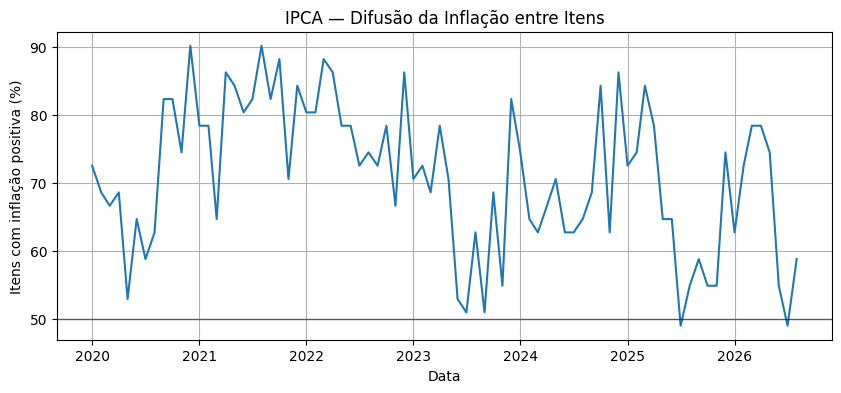

In [40]:
data_inicio_10a = (
    itens["date"].max()
    - pd.DateOffset(years=10)
)

difusao_10a = (
    difusao_itens[
        difusao_itens.index
        >= data_inicio_10a
    ]
)

plt.figure(figsize=(10, 4))

plt.plot(
    difusao_10a.index,
    difusao_10a["difusao"] * 100,
)

plt.axhline(
    50,
    color="black",
    linewidth=1,
    alpha=0.5,
)

plt.title(
    "IPCA — Difusão da Inflação entre Itens"
)

plt.xlabel("Data")
plt.ylabel("Itens com inflação positiva (%)")

plt.grid(True)

plt.show()

### 26. Interpretação da difusão

Duas observações com o mesmo IPCA agregado podem representar
situações bastante diferentes.

```text
        IPCA elevado
            +
      difusão elevada
            |
            v
aumento disseminado dos preços
```

versus:

```text
        IPCA elevado
            +
       difusão baixa
            |
            v
   movimento concentrado
   em poucos componentes
```

A difusão começa a se tornar ainda mais informativa no nível de itens
porque temos mais componentes que no nível de grupos ou subgrupos.

---

## PARTE IV — CONCENTRAÇÃO DAS PRESSÕES



### 27. Por que medir concentração?

`impacto` responde:

> Qual a magnitude da pressão de cada item?

Podemos agora fazer outra pergunta:

> Quanto das pressões observadas está concentrado em poucos itens?

Seja:

$$
I_t^{total}=\sum_{i=1}^{N_t} I_{i,t}
$$

Esse valor NÃO representa a inflação agregada.

Ele representa a soma das magnitudes das pressões individuais.

### 28. Impacto total por mês

In [41]:
impacto_mensal = (
    itens
    .groupby(
        "date",
        as_index=False,
    )["impacto"]
    .sum()
    .rename(
        columns={
            "impacto":
            "impacto_total"
        }
    )
)

impacto_mensal.tail(12)

,date,impacto_total
68,2025-09-01,0.9091
69,2025-10-01,0.5337
70,2025-11-01,0.6122
71,2025-12-01,0.6653
72,2026-01-01,0.8947
73,2026-02-01,0.9192
74,2026-03-01,0.9197
75,2026-04-01,0.9778
76,2026-05-01,0.8918
77,2026-06-01,0.4563


### 29. Participação dos 5 maiores impactos

Para cada mês calculamos:

$$
K_{5,t}=\frac{\sum_{i \in Top5_t} I_{i,t}}{\sum_{i=1}^{N_t} I_{i,t}}
$$

Quanto maior $K_{5,t}$, maior a concentração das pressões em poucos itens.

In [42]:
def concentracao_top_n(grupo, n=5):

    impactos = (
        grupo["impacto"]
        .sort_values(
            ascending=False
        )
    )

    total = impactos.sum()

    if total == 0:
        return 0.0

    return (
        impactos.head(n).sum()
        / total
    )

In [43]:
concentracao_5 = (
    itens
    .groupby("date")
    .apply(
        concentracao_top_n,
        n=5,
        include_groups=False,
    )
    .rename("concentracao_top5")
    .to_frame()
)

concentracao_5.tail(12)

,concentracao_top5
date,
2025-09-01,0.6523
2025-10-01,0.4475
2025-11-01,0.4322
2025-12-01,0.5015
2026-01-01,0.4805
2026-02-01,0.5935
2026-03-01,0.6229
2026-04-01,0.4857
2026-05-01,0.6326


### 30. Evolução da concentração

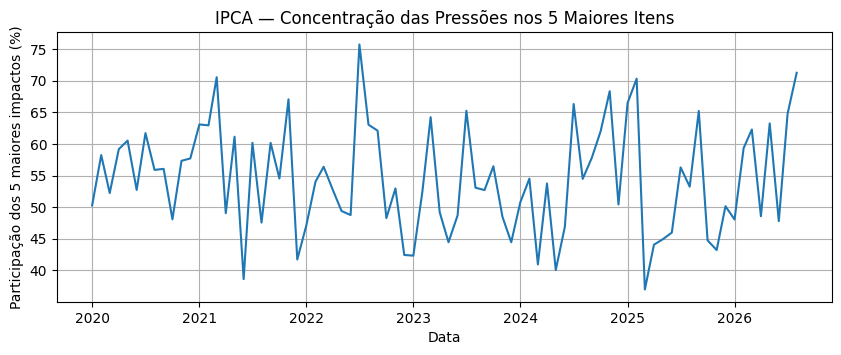

In [46]:
concentracao_10a = (
    concentracao_5[
        concentracao_5.index
        >= data_inicio_10a
    ]
)

plt.figure(figsize=(10, 3.5))

plt.plot(
    concentracao_10a.index,
    concentracao_10a[
        "concentracao_top5"
    ] * 100,
)

plt.title(
    "IPCA — Concentração das Pressões nos 5 Maiores Itens"
)

plt.xlabel("Data")
plt.ylabel("Participação dos 5 maiores impactos (%)")

plt.grid(True)

plt.show()

### 31. Difusão versus concentração

Essas duas medidas são complementares.

* **Difusão alta + concentração baixa**

```text
     muitos itens subindo
            +
    impactos distribuídos
            |
            v
    inflação disseminada
```

* **Difusão baixa + concentração alta**

```text
    poucos itens dominando
        os movimentos
            |
            v
    inflação concentrada
```

* **Portanto**:

    * **difusão** $\to\qquad$ quantos componentes subiram?
    * **concentração** $\to\qquad$ poucos componentes dominam os impactos?


---

## PARTE V — ANÁLISE HIERÁRQUICA



### 32. Selecionar um subgrupo

Com muitos itens, comparar todas as séries simultaneamente não é
eficiente.

Utilizaremos uma análise hierárquica:

```text
selecionar subgrupo
       |
       v
analisar seus itens
```

In [47]:
subgrupo_escolhido = (
    subgrupos_ref
    .sort_values("subgrupo_codigo")
    .iloc[0]["subgrupo_nome"]
)

subgrupo_escolhido

'Alimentação no domicílio'

O subgrupo pode ser selecionado explicitamente, por exemplo:

```python
subgrupo_escolhido = "..."
```

In [48]:
itens_subgrupo = (
    itens[
        itens["subgrupo_nome"]
        == subgrupo_escolhido
    ]
    .copy()
)

itens_subgrupo[
    [
        "categoria",
        "categoria_nome",
    ]
].drop_duplicates()

,categoria,categoria_nome
0,1101,"Cereais, leguminosas e oleaginosas"
1,1102,"Farinhas, féculas e massas"
2,1103,"Tubérculos, raízes e legumes"
3,1104,Açúcares e derivados
4,1105,Hortaliças e verduras
5,1106,Frutas
6,1107,Carnes
7,1108,Pescados
8,1109,Carnes e peixes industrializados
9,1110,Aves e ovos


### 33. Itens do subgrupo no último mês

In [50]:
itens_subgrupo_ultimo = (
    itens_subgrupo[
        itens_subgrupo["date"]
        == ultimo_mes
    ]
    .sort_values(
        "impacto",
        ascending=False,
    )
)

itens_subgrupo_ultimo[
    [
        "categoria_nome",
        "indice",
        "peso",
        "contribuicao",
        "impacto",
        "direcao",
    ]
]

,categoria_nome,indice,peso,contribuicao,impacto,direcao
4031,"Tubérculos, raízes e legumes",-12.3700,0.8393,-0.1038,0.1038,negativa
4039,Leites e derivados,1.0600,1.8920,0.0201,0.0201,positiva
4038,Aves e ovos,-1.5500,1.2142,-0.0188,0.0188,negativa
4035,Carnes,0.6100,2.8281,0.0173,0.0173,positiva
4042,Bebidas e infusões,-0.5200,1.8662,-0.0097,0.0097,negativa
4034,Frutas,0.8400,1.1372,0.0096,0.0096,positiva
4037,Carnes e peixes industrializados,-0.9600,0.5954,-0.0057,0.0057,negativa
4033,Hortaliças e verduras,-1.6100,0.2613,-0.0042,0.0042,negativa
4040,Panificados,0.1400,1.6942,0.0024,0.0024,positiva
4043,Enlatados e conservas,0.6300,0.1601,0.0010,0.0010,positiva


### 34. Pressões dentro do subgrupo

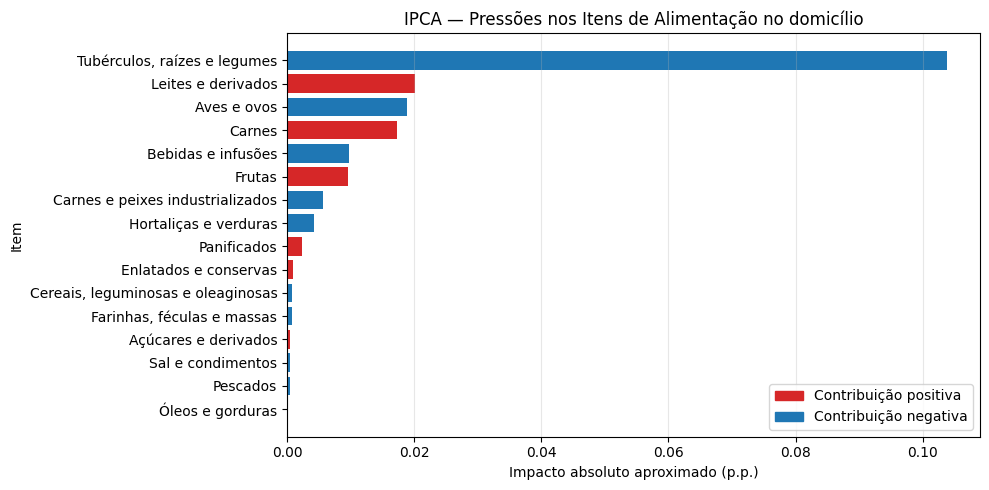

In [53]:
from matplotlib.patches import Patch

pressao_subgrupo = (
    itens_subgrupo_ultimo
    .sort_values("impacto")
)

cores = np.where(
    pressao_subgrupo["contribuicao"] >= 0,
    "tab:red",
    "tab:blue",
)

plt.figure(figsize=(10, 5))

plt.barh(
    pressao_subgrupo["categoria_nome"],
    pressao_subgrupo["impacto"],
    color=cores,
)

plt.title(
    f"IPCA — Pressões nos Itens de {subgrupo_escolhido}"
)

plt.xlabel("Impacto absoluto aproximado (p.p.)")
plt.ylabel("Item")

plt.grid(
    True,
    axis="x",
    alpha=0.3,
)

legenda = [
    Patch(
        color="tab:red",
        label="Contribuição positiva",
    ),
    Patch(
        color="tab:blue",
        label="Contribuição negativa",
    ),
]

plt.legend(
    handles=legenda,
    loc="lower right",
)

plt.tight_layout()
plt.show()

### 35. Direção das pressões dentro do subgrupo

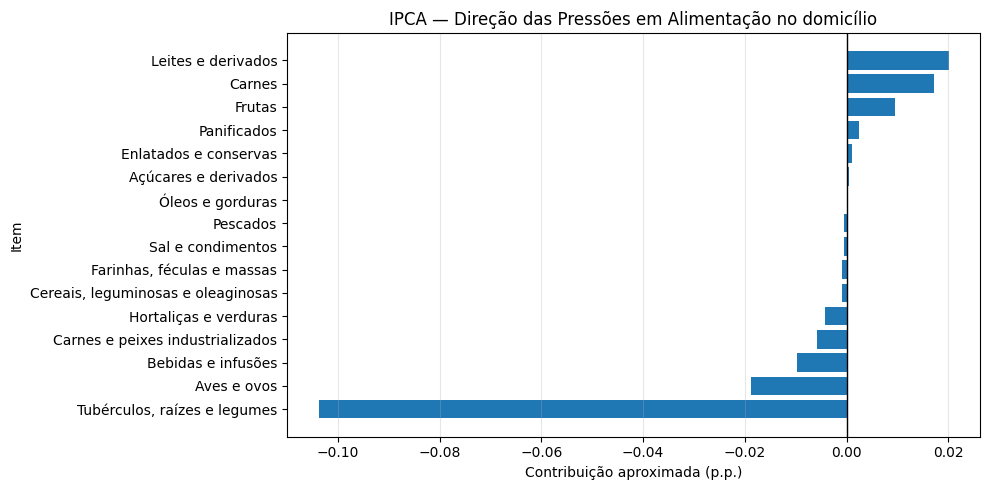

In [55]:
direcao_subgrupo = (
    itens_subgrupo_ultimo
    .sort_values("contribuicao")
)

plt.figure(figsize=(10, 5))

plt.barh(
    direcao_subgrupo["categoria_nome"],
    direcao_subgrupo["contribuicao"],
)

plt.axvline(
    0,
    color="black",
    linewidth=1,
)

plt.title(
    f"IPCA — Direção das Pressões em {subgrupo_escolhido}"
)

plt.xlabel("Contribuição aproximada (p.p.)")
plt.ylabel("Item")

plt.grid(
    True,
    axis="x",
    alpha=0.3,
)

plt.tight_layout()
plt.show()

---

## PARTE VI — CONSISTÊNCIA COM OS SUBGRUPOS



### 36. Relação hierárquica

Se $s$ representa um subgrupo e $i \in s$ representa seus itens,
esperamos aproximadamente:

$$
C_{s,t}\approx\sum_{i \in s} C_{i,t}
$$

A reconstrução precisa utilizar contribuição com sinal.

Não podemos utilizar impacto porque:

$$
\sum_i |C_{i,t}|\neq\left|\sum_i C_{i,t}\right|
$$

### 37. Carregar subgrupos para comparação

In [56]:
subgrupos_comparacao = pd.read_sql(
    """
    SELECT
        date,
        categoria,
        categoria_nome,
        indice,
        peso
    FROM bcb.ipca_subgrupos
    ORDER BY date, categoria;
    """,
    engine,
)

subgrupos_comparacao[
    "date"
] = pd.to_datetime(
    subgrupos_comparacao["date"]
)

subgrupos_comparacao[
    "categoria"
] = (
    subgrupos_comparacao[
        "categoria"
    ]
    .astype(str)
)

subgrupos_comparacao[
    "contribuicao_subgrupo"
] = (
    subgrupos_comparacao["indice"]
    * subgrupos_comparacao["peso"]
    / 100
)

### 38. Somar contribuições dos itens

In [57]:
contrib_itens = (
    itens
    .groupby(
        [
            "date",
            "subgrupo_codigo",
        ],
        as_index=False,
    )["contribuicao"]
    .sum()
    .rename(
        columns={
            "contribuicao":
            "contribuicao_itens"
        }
    )
)

### 39. Comparar subgrupo e soma dos itens

In [59]:
comparacao_hierarquia = (
    subgrupos_comparacao[
        [
            "date",
            "categoria",
            "categoria_nome",
            "contribuicao_subgrupo",
        ]
    ]
    .rename(
        columns={
            "categoria":
            "subgrupo_codigo",
            "categoria_nome":
            "subgrupo_nome",
        }
    )
    .merge(
        contrib_itens,
        on=[
            "date",
            "subgrupo_codigo",
        ],
        how="inner",
        validate="one_to_one",
    )
)

comparacao_hierarquia[
    "erro_reconstrucao"
] = (
    comparacao_hierarquia[
        "contribuicao_itens"
    ]
    - comparacao_hierarquia[
        "contribuicao_subgrupo"
    ]
)

comparacao_hierarquia[
    "erro_abs"
] = (
    comparacao_hierarquia[
        "erro_reconstrucao"
    ]
    .abs()
)

comparacao_hierarquia.tail(15)

,date,subgrupo_codigo,subgrupo_nome,contribuicao_subgrupo,contribuicao_itens,erro_reconstrucao,erro_abs
1505,2026-08-01,31,Móveis e utensílios,0.0067,0.0066,-0.0001,0.0001
1506,2026-08-01,32,Aparelhos eletroeletrônicos,0.0156,0.0156,0.0000,0.0000
1507,2026-08-01,33,Consertos e manutenção,0.0000,0.0000,0.0000,0.0000
1508,2026-08-01,41,Roupas,-0.0030,-0.0029,0.0001,0.0001
1509,2026-08-01,42,Calçados e acessórios,0.0091,0.0091,0.0000,0.0000
1510,2026-08-01,43,Joias e bijuterias,-0.0004,-0.0004,0.0000,0.0000
1511,2026-08-01,44,Tecidos e armarinho,-0.0001,-0.0001,0.0000,0.0000
1512,2026-08-01,51,Transportes,-0.1743,-0.1734,0.0009,0.0009
1513,2026-08-01,61,Produtos farmacêuticos e óticos,0.0111,0.0112,0.0001,0.0001
1514,2026-08-01,62,Serviços de saúde,0.0226,0.0227,0.0001,0.0001


### 40. Erro de reconstrução

Definimos:

$$
\varepsilon_{s,t}=\left(\sum_{i \in s} C_{i,t}\right)-C_{s,t}
$$

e:

$$
E_{s,t}=|\varepsilon_{s,t}|
$$

In [60]:
comparacao_hierarquia[
    "erro_reconstrucao"
].describe()

count   1520.0000
mean       0.0000
std        0.0002
min       -0.0016
25%       -0.0000
50%        0.0000
75%        0.0000
max        0.0019
Name: erro_reconstrucao, dtype: float64

### 41. Maiores erros observados

In [64]:
comparacao_hierarquia.nlargest(
    15,
    "erro_abs",
)[
    [
        "date",
        "subgrupo_nome",
        "contribuicao_subgrupo",
        "contribuicao_itens",
        "erro_reconstrucao",
        "erro_abs",
    ]
]

,date,subgrupo_nome,contribuicao_subgrupo,contribuicao_itens,erro_reconstrucao,erro_abs
847,2023-09-01,Transportes,0.2896,0.2914,0.0019,0.0019
1037,2024-07-01,Transportes,0.3722,0.3706,-0.0016,0.0016
467,2022-01-01,Transportes,-0.0241,-0.0225,0.0016,0.0016
657,2022-11-01,Transportes,0.1696,0.1680,-0.0016,0.0016
1360,2025-12-01,Transportes,0.1502,0.1488,-0.0015,0.0015
30,2020-02-01,Transportes,-0.0474,-0.0460,0.0014,0.0014
828,2023-08-01,Transportes,0.0703,0.0717,0.0014,0.0014
391,2021-09-01,Transportes,0.3821,0.3807,-0.0014,0.0014
961,2024-03-01,Transportes,-0.0683,-0.0696,-0.0013,0.0013
1056,2024-08-01,Transportes,0.0000,0.0013,0.0013,0.0013


---

## PARTE VII — PRESSÕES HISTÓRICAS



### 42. Item de maior impacto em cada mês

Para cada período:

$$
i_t^*=\arg\max_i I_{i,t}
$$

identifica o item de maior impacto absoluto.

In [65]:
idx_maior_impacto = (
    itens
    .groupby("date")["impacto"]
    .idxmax()
)

maior_impacto_mes = (
    itens.loc[
        idx_maior_impacto,
        [
            "date",
            "grupo_nome",
            "subgrupo_nome",
            "categoria_nome",
            "indice",
            "peso",
            "contribuicao",
            "impacto",
            "direcao",
        ],
    ]
    .sort_values("date")
    .reset_index(drop=True)
)

maior_impacto_mes.tail(12)

,date,grupo_nome,subgrupo_nome,categoria_nome,indice,peso,contribuicao,impacto,direcao
68,2025-09-01,Habitação,Combustíveis e energia,Energia elétrica residencial,10.3100,3.9533,0.4076,0.4076,positiva
69,2025-10-01,Habitação,Combustíveis e energia,Energia elétrica residencial,-2.3900,4.3401,-0.1037,0.1037,negativa
70,2025-11-01,Transportes,Transportes,Transporte público,2.4800,3.0059,0.0745,0.0745,positiva
71,2025-12-01,Transportes,Transportes,Transporte público,3.4800,3.0756,0.1070,0.1070,positiva
72,2026-01-01,Transportes,Transportes,Combustíveis (veículos),2.1400,6.0495,0.1295,0.1295,positiva
73,2026-02-01,Educação,"Cursos, leitura e papelaria",Cursos regulares,6.2000,4.5392,0.2814,0.2814,positiva
74,2026-03-01,Transportes,Transportes,Combustíveis (veículos),4.4700,6.0887,0.2722,0.2722,positiva
75,2026-04-01,Transportes,Transportes,Transporte público,-4.0000,3.2339,-0.1294,0.1294,negativa
76,2026-05-01,Alimentação e bebidas,Alimentação no domicílio,"Tubérculos, raízes e legumes",21.4000,0.8206,0.1756,0.1756,positiva
77,2026-06-01,Transportes,Transportes,Transporte público,2.1100,3.0954,0.0653,0.0653,positiva


### 43. Itens que mais vezes lideraram a pressão

In [66]:
frequencia_impacto = (
    maior_impacto_mes[
        "categoria_nome"
    ]
    .value_counts()
    .rename("meses")
    .to_frame()
)

frequencia_impacto.head(20)

,meses
categoria_nome,
Combustíveis (veículos),25
Energia elétrica residencial,20
Transporte público,12
Cursos regulares,6
Carnes,4
"Tubérculos, raízes e legumes",4
Veículo próprio,3
Produtos farmacêuticos,2
Higiene pessoal,1


### 44. Maiores impactos históricos

In [68]:
itens.nlargest(
    10,
    "impacto",
)[
    [
        "date",
        "grupo_nome",
        "subgrupo_nome",
        "categoria_nome",
        "indice",
        "peso",
        "contribuicao",
        "impacto",
        "direcao",
    ]
]

,date,grupo_nome,subgrupo_nome,categoria_nome,indice,peso,contribuicao,impacto,direcao
1566,2022-07-01,Transportes,Transportes,Combustíveis (veículos),-14.1500,8.0210,-1.1350,1.1350,negativa
1617,2022-08-01,Transportes,Transportes,Combustíveis (veículos),-10.8200,6.9377,-0.7507,0.7507,negativa
750,2021-03-01,Transportes,Transportes,Combustíveis (veículos),11.2300,6.2907,0.7064,0.7064,positiva
1158,2021-11-01,Transportes,Transportes,Combustíveis (veículos),7.7400,7.4970,0.5803,0.5803,positiva
189,2020-04-01,Transportes,Transportes,Combustíveis (veículos),-9.5900,5.9703,-0.5726,0.5726,negativa
3132,2025-02-01,Habitação,Combustíveis e energia,Energia elétrica residencial,16.8000,3.3082,0.5558,0.5558,positiva
3081,2025-01-01,Habitação,Combustíveis e energia,Energia elétrica residencial,-14.2100,3.8621,-0.5488,0.5488,negativa
1668,2022-09-01,Transportes,Transportes,Combustíveis (veículos),-8.5000,6.2116,-0.5280,0.5280,negativa
1362,2022-03-01,Transportes,Transportes,Combustíveis (veículos),6.7000,7.5830,0.5081,0.5081,positiva
699,2021-02-01,Transportes,Transportes,Combustíveis (veículos),7.0900,5.9249,0.4201,0.4201,positiva


---

## PARTE VIII — REPRESENTAÇÕES ANALÍTICAS



### 45. Formato longo

In [71]:
itens_analitico = itens[
    [
        "date",
        "grupo_codigo",
        "grupo_nome",
        "subgrupo_codigo",
        "subgrupo_nome",
        "categoria",
        "categoria_nome",
        "indice",
        "peso",
        "contribuicao",
        "impacto",
        "direcao",
    ]
].copy()

itens_analitico.tail(10)

,date,grupo_codigo,grupo_nome,subgrupo_codigo,subgrupo_nome,categoria,categoria_nome,indice,peso,contribuicao,impacto,direcao
4070,2026-08-01,6,Saúde e cuidados pessoais,62,Serviços de saúde,6203,Plano de saúde,0.4200,4.1405,0.0174,0.0174,positiva
4071,2026-08-01,6,Saúde e cuidados pessoais,63,Cuidados pessoais,6301,Higiene pessoal,-0.0400,4.1025,-0.0016,0.0016,negativa
4072,2026-08-01,7,Despesas pessoais,71,Serviços pessoais,7101,Serviços pessoais,0.3700,6.3498,0.0235,0.0235,positiva
4073,2026-08-01,7,Despesas pessoais,72,Recreação e fumo,7201,Recreação,-0.1200,3.3143,-0.0040,0.0040,negativa
4074,2026-08-01,7,Despesas pessoais,72,Recreação e fumo,7202,Fumo,19.5900,0.5785,0.1133,0.1133,positiva
4075,2026-08-01,8,Educação,81,"Cursos, leitura e papelaria",8101,Cursos regulares,0.5200,4.6754,0.0243,0.0243,positiva
4076,2026-08-01,8,Educação,81,"Cursos, leitura e papelaria",8102,Leitura,0.2600,0.5432,0.0014,0.0014,positiva
4077,2026-08-01,8,Educação,81,"Cursos, leitura e papelaria",8103,Papelaria,0.4900,0.1391,0.0007,0.0007,positiva
4078,2026-08-01,8,Educação,81,"Cursos, leitura e papelaria",8104,Cursos diversos,0.3600,0.8023,0.0029,0.0029,positiva
4079,2026-08-01,9,Comunicação,91,Comunicação,9101,Comunicação,-0.0900,4.5011,-0.0041,0.0041,negativa


### 46. Matriz de variações

In [72]:
indice_pivot = (
    itens
    .pivot(
        index="date",
        columns="categoria_nome",
        values="indice",
    )
    .sort_index()
)

indice_pivot.tail(12)

categoria_nome,Alimentação fora do domicílio,Aluguel e taxas,Artigos de limpeza,Aves e ovos,Açúcares e derivados,Bebidas e infusões,Calçados e acessórios,"Cama, mesa e banho",Carnes,Carnes e peixes industrializados,"Cereais, leguminosas e oleaginosas",Combustíveis (domésticos),Combustíveis (veículos),Comunicação,Consertos e manutenção,Cursos diversos,Cursos regulares,Eletrodomésticos e equipamentos,Energia elétrica residencial,Enlatados e conservas,"Farinhas, féculas e massas",Frutas,Fumo,Higiene pessoal,Hortaliças e verduras,Joias e bijuterias,Leites e derivados,Leitura,Mobiliário,Panificados,Papelaria,Pescados,Plano de saúde,Produtos farmacêuticos,Produtos óticos,Recreação,Reparos,Roupa feminina,Roupa infantil,Roupa masculina,Sal e condimentos,Serviços laboratoriais e hospitalares,Serviços médicos e dentários,Serviços pessoais,Tecidos e armarinho,Transporte público,"Tubérculos, raízes e legumes","Tv, som e informática",Utensílios e enfeites,Veículo próprio,Óleos e gorduras
date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2025-09-01,0.1100,0.3200,0.1900,-1.2000,0.4500,-0.0300,0.3000,-0.1600,-0.1200,-0.0100,-1.9700,0.5600,0.8700,-0.1700,1.6500,0.0800,0.0000,-1.5400,10.3100,0.0500,-0.4200,2.4000,-0.8300,-0.3200,-2.6500,1.3700,-0.2000,0.4600,0.3800,0.6500,0.7000,-1.7500,0.5000,0.2300,0.3400,1.1500,0.6600,0.3600,0.7600,1.0600,-2.4600,0.3300,0.3900,0.2900,0.3800,-0.2800,-7.8500,-1.5900,-0.3200,-0.3700,1.6300
2025-10-01,0.4600,0.5300,-0.1500,-0.5100,0.7900,-0.1200,0.8900,0.4000,0.2100,-0.2000,-1.8300,0.8400,0.3200,-0.1600,0.8100,0.3200,0.0000,-0.5900,-2.3900,0.3600,-0.4600,-0.6900,-0.0700,0.5700,-0.5500,1.4100,-1.0300,0.2500,-0.1800,-0.0700,-0.3200,0.2500,0.5000,0.2200,-0.3700,0.5500,0.3300,0.5600,0.2800,0.0100,-1.5600,0.2100,0.3900,0.4400,-0.2800,1.1700,2.3500,-1.2400,-0.2800,-0.2800,2.1800
2025-11-01,0.4600,0.3600,-0.1100,-0.3900,0.3800,-0.4500,0.1000,-0.5600,1.0500,-0.1700,-2.2200,-0.3200,-0.3200,-0.2000,-0.1200,0.2800,0.0000,-2.4400,1.2700,0.2800,0.2600,0.5000,0.0000,-1.0700,1.9000,1.3300,-2.2700,-0.1700,0.1900,0.6400,-0.5100,0.5500,0.5000,0.2400,-0.1800,1.5300,0.3600,0.6800,0.4000,0.5300,-0.0600,0.2200,0.6400,0.4300,0.5500,2.4800,-2.7700,-2.2800,-0.5700,-0.1000,1.1900
2025-12-01,0.6000,0.5400,0.5600,0.2600,0.5700,0.0200,0.7500,-0.4000,1.4800,0.3100,-1.6600,-0.1100,0.4500,0.3700,0.8800,0.2000,0.0000,0.0000,-2.4100,0.0500,0.1900,1.2600,0.0000,0.5200,-0.6900,0.5700,-2.2700,0.3500,0.8500,0.2200,0.7100,0.5500,0.4900,0.3900,1.7500,0.0900,0.5200,-0.1300,0.9800,0.5400,-1.0700,0.3500,0.8500,0.5400,0.2300,3.4800,1.6800,1.9700,-0.4100,0.1300,-0.2400
2026-01-01,0.5500,1.1200,0.5600,-1.7000,-0.2300,-0.2900,0.2800,0.4700,0.8400,-0.1700,-1.2700,0.0500,2.1400,0.8200,0.5200,-0.3800,0.0000,-0.1300,-2.7300,0.6900,-0.1100,0.9500,0.1200,1.2000,5.2300,2.2100,-2.3100,0.9400,-0.0800,0.3600,-0.7300,2.7700,0.4900,0.1800,1.2000,0.4900,0.3900,-0.9600,-0.3700,-0.5100,-0.3500,1.0400,1.0500,0.3900,0.2900,-1.6400,7.6300,0.8900,0.3200,0.4000,-2.0600
2026-02-01,0.3400,0.4300,-0.3500,0.6700,0.7500,0.6700,0.4000,0.2900,0.5800,0.7500,0.1300,-0.1300,-0.4700,0.1500,0.5500,3.2400,6.2000,-0.3200,0.3300,0.6700,0.1900,-2.7800,0.9000,0.9200,3.9000,2.8200,0.6800,1.4300,-0.0900,0.2800,-0.4400,0.1100,0.4900,0.3500,-0.4200,-0.5400,0.2100,0.2900,-1.0200,-0.2600,-0.5400,0.4200,0.8700,0.7500,0.0400,3.4500,0.0600,1.0200,-0.0500,0.6500,-1.5500
2026-03-01,0.6100,0.1900,0.5500,0.9200,-0.6300,0.7800,0.3000,-1.0000,1.7300,0.0800,2.7800,-0.1800,4.4700,0.1900,1.1100,0.3700,0.0000,-0.1500,0.1300,0.4500,0.7900,0.5000,0.7300,0.4000,2.1900,1.8400,4.2600,-0.3900,0.4500,0.3900,0.3500,1.8900,0.4900,0.3400,0.5600,0.4600,0.9300,-0.0500,0.9700,0.6500,-0.3200,0.4300,0.4000,0.7400,-0.4100,2.1700,16.7800,1.9300,0.0200,-0.0500,-0.4500
2026-04-01,0.5900,0.1600,0.3700,-0.5600,-0.4900,-0.3100,0.5600,0.0400,1.5900,-0.1900,2.5700,3.3100,1.8000,0.5700,0.6200,0.2700,0.0000,1.0500,0.7200,0.1400,0.0600,1.2200,0.0000,1.5700,2.7300,1.2200,5.9500,0.1600,0.6200,0.4900,0.5600,0.9900,0.4900,1.7700,-0.5300,

### 47. Matriz de contribuições

In [73]:
contribuicao_pivot = (
    itens
    .pivot(
        index="date",
        columns="categoria_nome",
        values="contribuicao",
    )
    .sort_index()
)

contribuicao_pivot.tail(12)

categoria_nome,Alimentação fora do domicílio,Aluguel e taxas,Artigos de limpeza,Aves e ovos,Açúcares e derivados,Bebidas e infusões,Calçados e acessórios,"Cama, mesa e banho",Carnes,Carnes e peixes industrializados,"Cereais, leguminosas e oleaginosas",Combustíveis (domésticos),Combustíveis (veículos),Comunicação,Consertos e manutenção,Cursos diversos,Cursos regulares,Eletrodomésticos e equipamentos,Energia elétrica residencial,Enlatados e conservas,"Farinhas, féculas e massas",Frutas,Fumo,Higiene pessoal,Hortaliças e verduras,Joias e bijuterias,Leites e derivados,Leitura,Mobiliário,Panificados,Papelaria,Pescados,Plano de saúde,Produtos farmacêuticos,Produtos óticos,Recreação,Reparos,Roupa feminina,Roupa infantil,Roupa masculina,Sal e condimentos,Serviços laboratoriais e hospitalares,Serviços médicos e dentários,Serviços pessoais,Tecidos e armarinho,Transporte público,"Tubérculos, raízes e legumes","Tv, som e informática",Utensílios e enfeites,Veículo próprio,Óleos e gorduras
date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2025-09-01,0.0067,0.0248,0.0014,-0.0158,0.0036,-0.0006,0.0036,-0.0003,-0.0033,-0.0001,-0.0151,0.0079,0.0525,-0.0078,0.0056,0.0006,0.0000,-0.0133,0.4076,0.0001,-0.0020,0.0279,-0.0050,-0.0128,-0.0066,0.0035,-0.0038,0.0025,0.0046,0.0111,0.0010,-0.0032,0.0206,0.0080,0.0008,0.0383,0.0087,0.0049,0.0045,0.0126,-0.0101,0.0020,0.0046,0.0182,0.0002,-0.0084,-0.0526,-0.0097,-0.0013,-0.0420,0.0071
2025-10-01,0.0278,0.0410,-0.0011,-0.0066,0.0063,-0.0024,0.0108,0.0007,0.0057,-0.0012,-0.0136,0.0118,0.0194,-0.0073,0.0028,0.0026,0.0000,-0.0050,-0.1037,0.0006,-0.0022,-0.0082,-0.0004,0.0227,-0.0013,0.0037,-0.0193,0.0014,-0.0022,-0.0012,-0.0005,0.0005,0.0206,0.0077,-0.0009,0.0184,0.0044,0.0076,0.0017,0.0001,-0.0062,0.0013,0.0046,0.0276,-0.0001,0.0348,0.0144,-0.0074,-0.0011,-0.0315,0.0096
2025-11-01,0.0279,0.0280,-0.0008,-0.0050,0.0030,-0.0090,0.0012,-0.0010,0.0285,-0.0010,-0.0162,-0.0045,-0.0194,-0.0091,-0.0004,0.0023,0.0000,-0.0204,0.0538,0.0005,0.0012,0.0059,0.0000,-0.0428,0.0045,0.0035,-0.0420,-0.0009,0.0023,0.0109,-0.0007,0.0010,0.0206,0.0084,-0.0004,0.0515,0.0048,0.0093,0.0024,0.0063,-0.0002,0.0013,0.0076,0.0271,0.0003,0.0745,-0.0174,-0.0134,-0.0022,-0.0112,0.0053
2025-12-01,0.0365,0.0420,0.0041,0.0033,0.0046,0.0004,0.0091,-0.0007,0.0405,0.0019,-0.0119,-0.0016,0.0272,0.0168,0.0030,0.0016,0.0000,0.0000,-0.1031,0.0001,0.0009,0.0149,0.0000,0.0205,-0.0017,0.0015,-0.0409,0.0019,0.0102,0.0038,0.0010,0.0010,0.0203,0.0136,0.0042,0.0031,0.0069,-0.0018,0.0058,0.0065,-0.0042,0.0021,0.0101,0.0341,0.0001,0.1070,0.0102,0.0113,-0.0016,0.0145,-0.0011
2026-01-01,0.0335,0.0873,0.0041,-0.0218,-0.0019,-0.0057,0.0034,0.0008,0.0233,-0.0010,-0.0089,0.0007,0.1295,0.0373,0.0018,-0.0031,0.0000,-0.0011,-0.1136,0.0011,-0.0005,0.0113,0.0007,0.0475,0.0126,0.0059,-0.0406,0.0052,-0.0010,0.0062,-0.0011,0.0051,0.0203,0.0063,0.0029,0.0167,0.0052,-0.0131,-0.0022,-0.0061,-0.0014,0.0062,0.0125,0.0247,0.0002,-0.0520,0.0471,0.0052,0.0012,0.0447,-0.0093
2026-02-01,0.0208,0.0338,-0.0026,0.0084,0.0060,0.0132,0.0049,0.0005,0.0162,0.0045,0.0009,-0.0018,-0.0289,0.0069,0.0019,0.0259,0.2814,-0.0026,0.0133,0.0011,0.0009,-0.0333,0.0053,0.0367,0.0098,0.0077,0.0116,0.0079,-0.0011,0.0048,-0.0006,0.0002,0.0204,0.0122,-0.0010,-0.0184,0.0028,0.0039,-0.0060,-0.0031,-0.0021,0.0025,0.0105,0.0475,0.0000,0.1073,0.0004,0.0060,-0.0002,0.0726,-0.0068
2026-03-01,0.0371,0.0149,0.0040,0.0115,-0.0051,0.0154,0.0037,-0.0017,0.0481,0.0005,0.0190,-0.0025,0.2722,0.0086,0.0038,0.0030,0.0000,-0.0012,0.0052,0.0007,0.0037,0.0058,0.0043,0.0160,0.0057,0.0051,0.0729,-0.0022,0.0054,0.0067,0.0005,0.0035,0.0203,0.0118,0.0013,0.0155,0.0123,-0.0007,0.0057,0.0077,-0.0012,0.0026,0.0048,0.0469,-0.0002,0.0693,0.1104,0.0114,0.0001,-0.0056,-0.0019
2026-04-01,0.0358,0.0125,0.0027,-0.0070,-0.0039,-0.0061,0.0068,0.0001,0.0446,-0.0011,0.0179,0.0455,0.1135,0.0258,0.0022,0.0022,0.0000,0.0083,0.0287,0.0002,0.0003,0.0141,0.0000,0.0625,0.0072,0.0034,0.1052,0.0009,0.0074,0.0083,0.0008,0.0019,0.0202,0.0611,-0.0013,-0

### 48. Matriz de impactos

In [74]:
impacto_pivot = (
    itens
    .pivot(
        index="date",
        columns="categoria_nome",
        values="impacto",
    )
    .sort_index()
)

impacto_pivot.tail(12)

categoria_nome,Alimentação fora do domicílio,Aluguel e taxas,Artigos de limpeza,Aves e ovos,Açúcares e derivados,Bebidas e infusões,Calçados e acessórios,"Cama, mesa e banho",Carnes,Carnes e peixes industrializados,"Cereais, leguminosas e oleaginosas",Combustíveis (domésticos),Combustíveis (veículos),Comunicação,Consertos e manutenção,Cursos diversos,Cursos regulares,Eletrodomésticos e equipamentos,Energia elétrica residencial,Enlatados e conservas,"Farinhas, féculas e massas",Frutas,Fumo,Higiene pessoal,Hortaliças e verduras,Joias e bijuterias,Leites e derivados,Leitura,Mobiliário,Panificados,Papelaria,Pescados,Plano de saúde,Produtos farmacêuticos,Produtos óticos,Recreação,Reparos,Roupa feminina,Roupa infantil,Roupa masculina,Sal e condimentos,Serviços laboratoriais e hospitalares,Serviços médicos e dentários,Serviços pessoais,Tecidos e armarinho,Transporte público,"Tubérculos, raízes e legumes","Tv, som e informática",Utensílios e enfeites,Veículo próprio,Óleos e gorduras
date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2025-09-01,0.0067,0.0248,0.0014,0.0158,0.0036,0.0006,0.0036,0.0003,0.0033,0.0001,0.0151,0.0079,0.0525,0.0078,0.0056,0.0006,0.0000,0.0133,0.4076,0.0001,0.0020,0.0279,0.0050,0.0128,0.0066,0.0035,0.0038,0.0025,0.0046,0.0111,0.0010,0.0032,0.0206,0.0080,0.0008,0.0383,0.0087,0.0049,0.0045,0.0126,0.0101,0.0020,0.0046,0.0182,0.0002,0.0084,0.0526,0.0097,0.0013,0.0420,0.0071
2025-10-01,0.0278,0.0410,0.0011,0.0066,0.0063,0.0024,0.0108,0.0007,0.0057,0.0012,0.0136,0.0118,0.0194,0.0073,0.0028,0.0026,0.0000,0.0050,0.1037,0.0006,0.0022,0.0082,0.0004,0.0227,0.0013,0.0037,0.0193,0.0014,0.0022,0.0012,0.0005,0.0005,0.0206,0.0077,0.0009,0.0184,0.0044,0.0076,0.0017,0.0001,0.0062,0.0013,0.0046,0.0276,0.0001,0.0348,0.0144,0.0074,0.0011,0.0315,0.0096
2025-11-01,0.0279,0.0280,0.0008,0.0050,0.0030,0.0090,0.0012,0.0010,0.0285,0.0010,0.0162,0.0045,0.0194,0.0091,0.0004,0.0023,0.0000,0.0204,0.0538,0.0005,0.0012,0.0059,0.0000,0.0428,0.0045,0.0035,0.0420,0.0009,0.0023,0.0109,0.0007,0.0010,0.0206,0.0084,0.0004,0.0515,0.0048,0.0093,0.0024,0.0063,0.0002,0.0013,0.0076,0.0271,0.0003,0.0745,0.0174,0.0134,0.0022,0.0112,0.0053
2025-12-01,0.0365,0.0420,0.0041,0.0033,0.0046,0.0004,0.0091,0.0007,0.0405,0.0019,0.0119,0.0016,0.0272,0.0168,0.0030,0.0016,0.0000,0.0000,0.1031,0.0001,0.0009,0.0149,0.0000,0.0205,0.0017,0.0015,0.0409,0.0019,0.0102,0.0038,0.0010,0.0010,0.0203,0.0136,0.0042,0.0031,0.0069,0.0018,0.0058,0.0065,0.0042,0.0021,0.0101,0.0341,0.0001,0.1070,0.0102,0.0113,0.0016,0.0145,0.0011
2026-01-01,0.0335,0.0873,0.0041,0.0218,0.0019,0.0057,0.0034,0.0008,0.0233,0.0010,0.0089,0.0007,0.1295,0.0373,0.0018,0.0031,0.0000,0.0011,0.1136,0.0011,0.0005,0.0113,0.0007,0.0475,0.0126,0.0059,0.0406,0.0052,0.0010,0.0062,0.0011,0.0051,0.0203,0.0063,0.0029,0.0167,0.0052,0.0131,0.0022,0.0061,0.0014,0.0062,0.0125,0.0247,0.0002,0.0520,0.0471,0.0052,0.0012,0.0447,0.0093
2026-02-01,0.0208,0.0338,0.0026,0.0084,0.0060,0.0132,0.0049,0.0005,0.0162,0.0045,0.0009,0.0018,0.0289,0.0069,0.0019,0.0259,0.2814,0.0026,0.0133,0.0011,0.0009,0.0333,0.0053,0.0367,0.0098,0.0077,0.0116,0.0079,0.0011,0.0048,0.0006,0.0002,0.0204,0.0122,0.0010,0.0184,0.0028,0.0039,0.0060,0.0031,0.0021,0.0025,0.0105,0.0475,0.0000,0.1073,0.0004,0.0060,0.0002,0.0726,0.0068
2026-03-01,0.0371,0.0149,0.0040,0.0115,0.0051,0.0154,0.0037,0.0017,0.0481,0.0005,0.0190,0.0025,0.2722,0.0086,0.0038,0.0030,0.0000,0.0012,0.0052,0.0007,0.0037,0.0058,0.0043,0.0160,0.0057,0.0051,0.0729,0.0022,0.0054,0.0067,0.0005,0.0035,0.0203,0.0118,0.0013,0.0155,0.0123,0.0007,0.0057,0.0077,0.0012,0.0026,0.0048,0.0469,0.0002,0.0693,0.1104,0.0114,0.0001,0.0056,0.0019
2026-04-01,0.0358,0.0125,0.0027,0.0070,0.0039,0.0061,0.0068,0.0001,0.0446,0.0011,0.0179,0.0455,0.1135,0.0258,0.0022,0.0022,0.0000,0.0083,0.0287,0.0002,0.0003,0.0141,0.0000,0.0625,0.0072,0.0034,0.1052,0.0009,0.0074,0.0083,0.0008,0.0019,0.0202,0.0611,0.0013,0.0070,0.0064,0.0101,0.0017,0.0022,0.0041,0.0035,0.0122,0.0424,0.0001,0.1294,0.0644,0.0050,0.0002,0.0277,0.0022
2026-05-01

---

## PARTE IX — IMPLICAÇÕES PARA MODELAGEM



### 49. Granularidade e dimensionalidade

O nível de itens aumenta significativamente o número de potenciais
preditores.

Em vez de utilizar diretamente:

$$
X_t =[item_{1,t},item_{2,t},\ldots,item_{N,t}]
$$

pode ser mais interessante construir estatísticas resumidas da estrutura
inflacionária.

### 50. Possíveis features agregadas

A partir deste notebook podemos construir futuramente:

* **Difusão**

$$
D_t
$$

* **Maior impacto**

$$
I_t^{max}=\max_i I_{i,t}
$$

* **Impacto total**

$$
I_t^{total}=\sum_i I_{i,t}
$$

* **Concentração dos maiores impactos**

$$
K_{5,t}=\frac{\sum_{i \in Top5_t} I_{i,t}}{I_t^{total}}
$$

* **Dispersão**

Podemos utilizar medidas como:

$$
\sigma_{\pi,t}
$$

representando a dispersão das variações entre itens.

### 51. Uma representação mais compacta

Em vez de dezenas de itens individuais, poderíamos futuramente ter:

$$
X_t=[IPCA_t,D_t,I_t^{max},I_t^{total},K_{5,t},\sigma_{\pi,t}]
$$

juntamente com:

- SELIC;
- defasagens do IPCA;
- outras variáveis macroeconômicas;
- eventualmente informações selecionadas de grupos e subgrupos.

Essa estrutura pode produzir menor dimensionalidade e maior
interpretabilidade.

### 52. Cuidados com leakage

As estatísticas deste notebook descrevem a composição do IPCA de um
determinado mês.

Portanto, se o objetivo for prever $\pi_{t+1}$, uma estrutura válida
poderia utilizar informações disponíveis até $t$:

$$
\hat{\pi}_{t+1}=f(D_t,I_t^{max},K_{5,t},\pi_t,SELIC_t,\ldots)
$$

Mas utilizar a decomposição de $t+1$ para prever o próprio IPCA de
$t+1$ constituiria vazamento de informação.

---

### 53. Conclusões

O nível de itens representa uma evolução importante da decomposição
da inflação.

* **Itens individuais**

Permitem identificar categorias mais específicas responsáveis pelos
movimentos observados.

* **Impacto**

Definimos:

$$
I_{i,t}=|C_{i,t}|
$$

como a magnitude da pressão exercida por cada item.

Quando falamos em:

- maior pressão;
- maior relevância;
- maior influência em magnitude;

utilizamos preferencialmente `impacto`.

** Contribuição

Mantemos:

$$
C_{i,t}=\pi_{i,t}\frac{w_{i,t}}{100}
$$

quando precisamos preservar a direção ou reconstruir agregações
hierárquicas.

* **Difusão**

$$
D_t=\frac{\sum_i\mathbf{1}(\pi_{i,t}>0)}{N_t}
$$

mede a abrangência da alta dos preços.

* **Concentração**

$$
K_{5,t}=\frac{\sum_{i \in Top5_t} I_{i,t}}{\sum_i I_{i,t}}
$$

mede quanto das pressões está concentrado nos componentes de maior
impacto.

---



#### Quatro dimensões da inflação

A partir deste notebook conseguimos separar:

* intensidade $\to\qquad$ quanto foi o IPCA?
* direção $\to\qquad$ quem contribuiu para cima ou para baixo?
* difusão $\to\qquad$ quantos componentes estão subindo?
* concentração $\to\qquad$ poucos componentes dominam as pressões?


Essa estrutura oferece uma representação mais rica do processo
inflacionário que o IPCA agregado isoladamente.

---

* **Próxima etapa**

```text
02.04.subitens
```

No nível de subitens a dimensionalidade será ainda maior.

Por isso, o foco deverá migrar ainda mais de séries individuais para:

- rankings;
- impacto;
- difusão;
- concentração;
- persistência;
- distribuição;
- medidas agregadas;
- seleção de componentes relevantes.